# Sentiment Classifier su videogames review — Learning da Film a Videogiochi + learning da zero


## 1. Definizione del Problema

**Obiettivo del Task:**
L’obiettivo del progetto è classificare una recensione testuale di un videogioco in una delle classi di sentiment definite, cercando non solo di capire quale sia il giudizio espresso dall’utente, ma anche di comprendere quali elementi della recensione abbiano contribuito a portare a tale classificazione.

**I 3 modelli:**

| | Architettura | Punto di partenza | Tecnica | 
|---|---|---|---|
| **M1** | DistilBERT | Wenfi (IMDB) | **LoRA** su giochi | 
| **M2** | DistilBERT | Pesi generici (no sentiment) | **Full fine-tuning** su giochi |
| **M3** | RoBERTa-large-MNLI | NLI generico | **Zero-shot**, nessun training | 
| **BERT** | BERT | Pesi generici (no sentiment) | **Full fine-tuning** su giochi | 

**LoRA per M1:** Questo ci permette di **proteggere** la
conoscenza di sentiment già acquisita da Wenfi sui film. In questo modo, tramite un full fine-tuning, non rischiamo di sovrascriverla.

**M2 e BERT:** invece partono da pesi **generici** (nessuna conoscenza di sentiment da
proteggere) e il dataset è abbastanza grande, quindi questo giustifica l'utilizzo di un full fine-tuning.

**roBERTa:** Essendo un modello linguistico avanzato, grazie al suo addestramento di base ci consente di determinare senza ulteriori training e tramite modalità "zero-shot", se un'ipotesi è vera (positiva), falsa (negativa) o neutrale (mixed)

In [ ]:
!pip install -q peft
!pip install captum
!pip install -q -U torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 8.6 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 32.8 MB/s eta 0:00:0000:0100:01


In [2]:
import os
import gc
import time
import shutil
import random
import numpy as np
import pandas as pd
import torch
import json
import math
import matplotlib.pyplot as plt
import seaborn as sns
import textwrap
from captum.attr import LayerIntegratedGradients
from IPython.display import display, HTML
from datasets import load_dataset, Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    pipeline,
)
from peft import PeftModel, LoraConfig, get_peft_model, TaskType
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix
from scipy.special import softmax


# Seed fisso su tutti i layer casuali (Python, NumPy, PyTorch) per garantire riproducibilità
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Rileva se il notebook gira su Kaggle e imposta i path di output di conseguenza
IS_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
OUTPUT_DIR = "/kaggle/working/results_sentiment" if IS_KAGGLE else "./results_sentiment"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# device=0 è il formato atteso dalle pipeline HuggingFace (GPU index), device_torch è il formato PyTorch
device       = 0 if torch.cuda.is_available() else -1
device_torch = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_fp16     = torch.cuda.is_available()

# Mapping bidirezionale tra indici interi e stringhe di classe
LABELS     = ["negative", "mixed", "positive"]
NUM_LABELS = len(LABELS)
id2label   = {0: "negative", 1: "mixed", 2: "positive"}
label2id   = {"negative": 0, "mixed": 1, "positive": 2}

print("Kaggle:", IS_KAGGLE, "| GPU disponibile:", torch.cuda.is_available())


def stampa_tabella(df, titolo=None, decimali=3, index=True):
    """Stampa un DataFrame con bordi ASCII e titolo centrato opzionale."""
    df_fmt = df.copy()
    colonne_numeriche = df_fmt.select_dtypes(include=["float", "float32", "float64"]).columns
    for col in colonne_numeriche:
        df_fmt[col] = df_fmt[col].round(decimali)

    testo    = df_fmt.to_string(index=index)
    larghezza = max(len(riga) for riga in testo.split("\n"))
    if titolo:
        larghezza = max(larghezza, len(titolo) + 4)

    print("=" * larghezza)
    if titolo:
        print(titolo.center(larghezza))
        print("-" * larghezza)
    print(testo)
    print("=" * larghezza)


# Cartelle di salvataggio per ogni modello, tutte dentro OUTPUT_DIR
SAVE_DIR  = f"{OUTPUT_DIR}/saved_models"
M3_DIR    = f"{SAVE_DIR}/m3"
M1_DIR    = f"{SAVE_DIR}/m1_lora_adapter"
M2_DIR    = f"{SAVE_DIR}/m2_distilbert"
BERT_DIR  = f"{SAVE_DIR}/bert_base"

# Se esiste un backup da una sessione precedente e SAVE_DIR non è ancora presente,
# lo copia in locale così tutti i blocchi if/else saltano il training automaticamente
PREV_OUTPUT = "/kaggle/input/datasets/lucacamiolo/modeldataset"
if os.path.isdir(PREV_OUTPUT) and not os.path.isdir(SAVE_DIR):
    shutil.copytree(PREV_OUTPUT, SAVE_DIR)
    print("Checkpoint copiati, training verrà saltato.")

for d in [M3_DIR, M1_DIR, M2_DIR, BERT_DIR]:
    os.makedirs(d, exist_ok=True)

Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.10.0+cu128).


Kaggle: True | GPU disponibile: True


## 2. Caricamento e pulizia del dataset di giochi

`auphong2707/game-reviews-sentiment` è un dataset che contiene solo le colonne
`review_text`, `review_score` (0-100) e `review_category`
(`positive`/`negative`/`mixed`).
Il dataset espone già tre split ufficiali indipendenti su Hugging Face (`train`, `validation`, `test`): li carichiamo e puliamo **separatamente**, e il bilanciamento delle classi avviene
**dentro ciascuno split**

**Pulizia applicata identicamente a ciascuno split:**
Filtra per lunghezza minima (≥100 parole) — recensioni troppo corte non sono informative



In [3]:
def carica_e_pulisci_split(nome_split):
    """
    Carica lo split richiesto ("train", "validation" o "test") da HuggingFace
    e applica la pulizia di base: filtro lunghezza minima (>= 100 parole) e
    mapping delle categorie in interi. Il bilanciamento per classe avviene
    separatamente in Sezione 3.
    """
    raw = load_dataset("auphong2707/game-reviews-sentiment", split=nome_split)
    df  = raw.to_pandas()

    df["word_count"] = df["review_text"].str.split().str.len()
    df = df[df["word_count"] >= 100].copy()

    # dropna rimuove le righe con categorie non presenti in label2id (valori anomali)
    df["label"] = df["review_category"].map(label2id)
    df = df.dropna(subset=["label"])
    df["label"] = df["label"].astype(int)

    return df


train_raw_df = carica_e_pulisci_split("train")
val_raw_df   = carica_e_pulisci_split("validation")
test_raw_df  = carica_e_pulisci_split("test")

for nome, d in [("Train", train_raw_df), ("Validation", val_raw_df), ("Test", test_raw_df)]:
    print(f"{nome}: {len(d)} recensioni dopo pulizia (>= 100 parole)")

README.md:   0%|          | 0.00/688 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/243M [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/30.5M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/30.3M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/629884 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/78735 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/78737 [00:00<?, ? examples/s]

Train: 206729 recensioni dopo pulizia (>= 100 parole)
Validation: 25733 recensioni dopo pulizia (>= 100 parole)
Test: 25725 recensioni dopo pulizia (>= 100 parole)


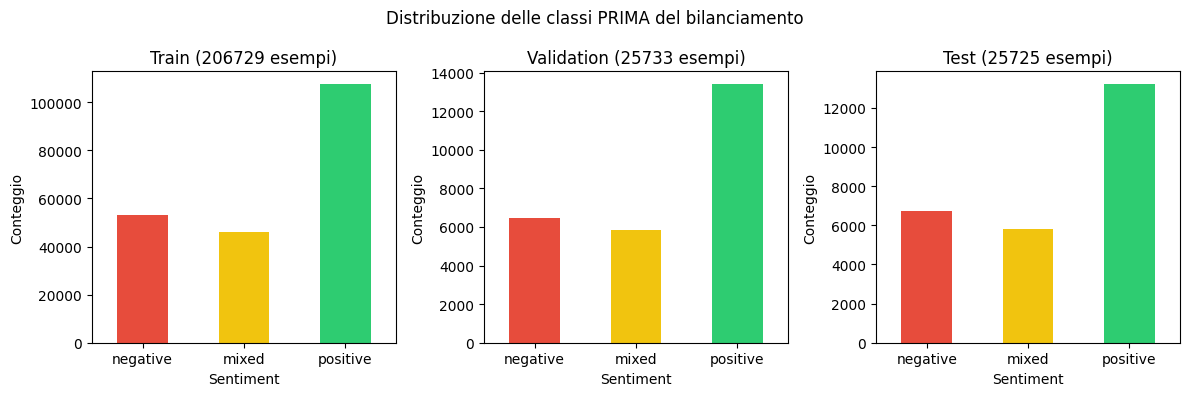

In [4]:
# Distribuzione delle classi per split, prima del bilanciamento
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, (nome, d) in zip(axes, [("Train", train_raw_df), ("Validation", val_raw_df), ("Test", test_raw_df)]):
    value_counts = d["review_category"].value_counts().reindex(["negative", "mixed", "positive"], fill_value=0)
    value_counts.plot(kind="bar", color=["#e74c3c", "#f1c40f", "#2ecc71"], ax=ax)
    ax.set_title(f"{nome} ({len(d)} esempi)")
    ax.set_xlabel("Sentiment")
    ax.set_ylabel("Conteggio")
    ax.tick_params(axis="x", rotation=0)

plt.suptitle("Distribuzione delle classi PRIMA del bilanciamento")
plt.tight_layout()
plt.show()

## 3. Campionamento bilanciato per split (train/validation/test ufficiali)

I dataset originali presentano una distribuzione delle classi non uniforme. Per evitare che eventuali differenze nella quantità di esempi per classe possano influenzare il confronto tra i modelli, viene applicata una procedura di campionamento bilanciato (70/15/15).

Per ciascuna classe di sentiment viene estratto casualmente lo stesso numero di esempi, fissato a priori in base allo split: 2800 campioni per classe nel training set e 600 campioni per classe nei set di validation e test. In questo modo vengono creati dataset con una distribuzione uniforme tra le tre categorie (Negativo, Misto e Positivo), permettendo di valutare i diversi modelli su dati con la stessa composizione tra le classi.

In [5]:
N_TRAIN_PER_CLASS = 2800
N_VAL_PER_CLASS   = 600
N_TEST_PER_CLASS  = 600


def campiona_bilanciato(df, n_per_classe, seed=SEED):
    """
    Estrae esattamente n_per_classe esempi per ciascuna delle 3 classi,
    mescolando il risultato finale. Se una classe ha meno campioni del
    richiesto, usa tutti quelli disponibili e avvisa.
    """
    pezzi = []
    for lbl in [0, 1, 2]:
        pool = df[df["label"] == lbl]
        n    = min(n_per_classe, len(pool))
        if n < n_per_classe:
            print(f"  [Attenzione] richiesti {n_per_classe} per label={lbl}, "
                  f"disponibili {len(pool)}: uso tutti quelli disponibili.")
        pezzi.append(pool.sample(n, random_state=seed))

    return pd.concat(pezzi).sample(frac=1, random_state=seed).reset_index(drop=True)


game_train_df = campiona_bilanciato(train_raw_df, N_TRAIN_PER_CLASS)
game_val_df   = campiona_bilanciato(val_raw_df,   N_VAL_PER_CLASS)
game_test_df  = campiona_bilanciato(test_raw_df,  N_TEST_PER_CLASS)

# Riepilogo degli split bilanciati: conteggi assoluti e percentuali per classe
split_summary_rows = []
for nome, d in [("Train", game_train_df), ("Validation", game_val_df), ("Test", game_test_df)]:
    conteggi     = d["label"].value_counts().sort_index()
    percentuali  = (d["label"].value_counts(normalize=True).sort_index() * 100).round(2)
    split_summary_rows.append({
        "Split"         : nome,
        "N. esempi"     : len(d),
        "N. negative (0)": int(conteggi.get(0, 0)),
        "N. mixed (1)"  : int(conteggi.get(1, 0)),
        "N. positive (2)": int(conteggi.get(2, 0)),
        "% negative"    : percentuali.get(0, 0.0),
        "% mixed"       : percentuali.get(1, 0.0),
        "% positive"    : percentuali.get(2, 0.0),
    })

df_split_summary = pd.DataFrame(split_summary_rows).set_index("Split")
stampa_tabella(df_split_summary, titolo="Struttura degli split (train/validation/test)")

                            Struttura degli split (train/validation/test)                             
------------------------------------------------------------------------------------------------------
            N. esempi  N. negative (0)  N. mixed (1)  N. positive (2)  % negative  % mixed  % positive
Split                                                                                                 
Train            8400             2800          2800             2800       33.33    33.33       33.33
Validation       1800              600           600              600       33.33    33.33       33.33
Test             1800              600           600              600       33.33    33.33       33.33


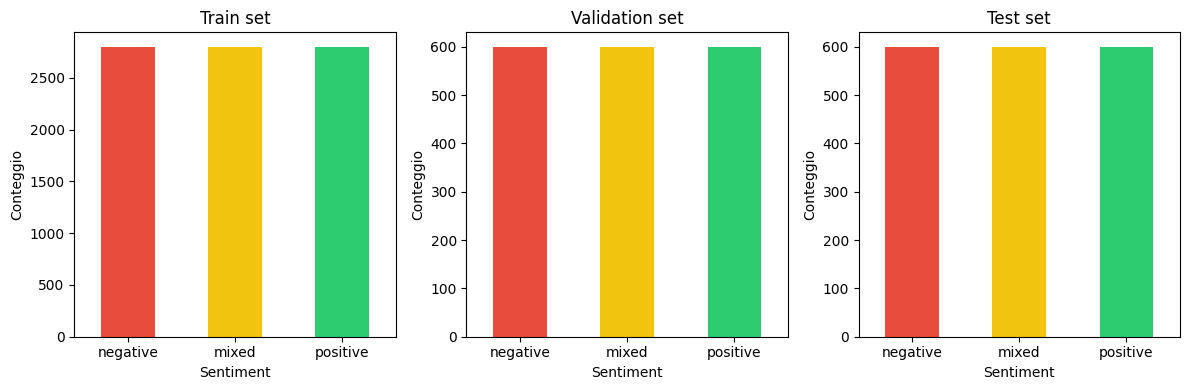

In [6]:
# Distribuzione delle classi per split, dopo il bilanciamento
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, (nome, df_split) in zip(axes, [("Train", game_train_df), ("Validation", game_val_df), ("Test", game_test_df)]):
    value_counts = df_split["review_category"].value_counts().reindex(["negative", "mixed", "positive"], fill_value=0)
    value_counts.plot(kind="bar", color=["#e74c3c", "#f1c40f", "#2ecc71"], ax=ax)
    ax.set_title(f"{nome} set")
    ax.set_xlabel("Sentiment")
    ax.set_ylabel("Conteggio")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

## 4. Funzioni di valutazione riutilizzabili

In questa sezione sono state raccolte le principali funzioni usate per effettuare quelle che sono le predizioni, valutazione dei modelli, visualizzazione dei risultati(grafici e tabellari) e per l’addestramento e la ricerca degli iperparametri migliori.

In [7]:
MAX_LENGTH = 256


def mostra_testo_evidenziato(token_attrib, titolo="Analisi XAI del Testo"):
    """
    Genera e mostra HTML con i token colorati in base alla loro attribuzione:
    verde per attribuzioni positive, rosso per negative, intensità proporzionale
    al valore assoluto normalizzato sul massimo del campione.
    """
    max_abs = max((abs(attr) for _, attr in token_attrib), default=1) or 1

    html_str = f"<h4>{titolo}</h4><p style='line-height: 1.8; font-size: 15px; font-family: sans-serif;'>"
    for word, attr in token_attrib:
        alpha = (abs(attr) / max_abs) * 0.7
        color = f"rgba(46, 204, 113, {alpha:.3f})" if attr > 0 else f"rgba(231, 76, 60, {alpha:.3f})"
        html_str += (
            f"<span style='background-color: {color}; padding: 2px 3px; "
            f"border-radius: 4px; margin: 0 1px; color: #000;'>{word}</span>"
        )
    html_str += "</p>"
    display(HTML(html_str))


def free_memory(trainer=None, model=None):
    """
    Elimina trainer e/o modello dalla RAM e svuota la cache CUDA.
    su Kaggle la VRAM non si libera automaticamente.
    """
    if trainer is not None:
        if hasattr(trainer, "model"):
            del trainer.model
        del trainer
    if model is not None:
        del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def evaluate_probs(y_true, probs, name):
    """
    Calcola le metriche di valutazione a partire da una matrice di probabilità
    (n_samples, n_classes). Restituisce un dizionario con accuracy, F1-macro,
    precision/recall per classe e AUC-ROC multiclasse (OvR).
    """
    preds      = np.argmax(probs, axis=-1)  # classe predetta = indice con probabilità massima
    acc        = accuracy_score(y_true, preds)
    f1_macro   = f1_score(y_true, preds, average="macro")

    # average=None restituisce un valore per classe, usato per le colonne per-classe nel result
    prec       = precision_score(y_true, preds, average=None, zero_division=0)
    rec        = recall_score(y_true, preds, average=None, zero_division=0)
    prec_macro = precision_score(y_true, preds, average="macro", zero_division=0)
    rec_macro  = recall_score(y_true, preds, average="macro", zero_division=0)

    try:
        # multi_class="ovr": per ogni classe calcola AUC come se fosse binaria (quella classe vs tutte le altre)
        auc = roc_auc_score(y_true, probs, multi_class="ovr", average="macro")
    except ValueError:
        # può fallire se nel batch manca almeno una classe (es. split molto piccoli)
        auc = float("nan")

    result = {
        "model": name, "accuracy": acc, "f1_macro": f1_macro,
        "precision_macro": prec_macro, "recall_macro": rec_macro,
        "precision_neg": prec[0], "precision_mixed": prec[1], "precision_pos": prec[2],
        "recall_neg": rec[0],     "recall_mixed": rec[1],     "recall_pos": rec[2],
        "roc_auc": auc,
    }
    print(f"[{name}] acc={acc:.3f} f1_macro={f1_macro:.3f} "
          f"precision_macro={prec_macro:.3f} recall_macro={rec_macro:.3f} auc={auc:.3f}")
    return result


def predict_with_torch_model(model, tokenizer, texts, batch_size=32, max_length=MAX_LENGTH):
    """
    Inferenza in batch su qualsiasi modello PyTorch.
    Restituisce una matrice di probabilità (n_samples, n_classes),
    compatibile con evaluate_probs.
    """
    model.eval()
    all_probs = []
    for i in range(0, len(texts), batch_size):
        batch  = texts[i:i + batch_size]
        inputs = tokenizer(batch, truncation=True, max_length=max_length, padding=True, return_tensors="pt")
        inputs = {k: v.to(model.device) for k, v in inputs.items()}
        with torch.no_grad():
            output = model(**inputs)
            # alcuni modelli restituiscono una tupla invece di un oggetto con .logits
            logits = output.logits if hasattr(output, "logits") else output[0]
        all_probs.append(torch.softmax(logits, dim=-1).detach().cpu().numpy())
    return np.concatenate(all_probs, axis=0)


def predict_zero_shot(zero_shot_pipe, texts, batch_size=32):
    """
    Inferenza in batch con la pipeline zero-shot HuggingFace.
    Restituisce una matrice (n_samples, n_classes) nello stesso formato
    di predict_with_torch_model, così entrambi passano per evaluate_probs.
    """
    all_probs = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i + batch_size]
        outs  = zero_shot_pipe(batch, candidate_labels=LABELS)

        # la pipeline restituisce un dict se il batch ha un solo elemento, lista altrimenti
        if isinstance(outs, dict):
            outs = [outs]

        for out in outs:
            # out["labels"] e out["scores"] sono allineati ma non necessariamente
            # nell'ordine di LABELS — il zip+dict garantisce il mapping corretto
            label_to_score = dict(zip(out["labels"], out["scores"]))
            all_probs.append([label_to_score[lbl] for lbl in LABELS])

    return np.array(all_probs)


def compute_metrics(eval_pred):
    """Callback per Trainer.evaluate(): restituisce accuracy e F1-macro."""
    logits, labels = eval_pred
    if isinstance(logits, tuple):  # guard per modelli che restituiscono tuple di output
        logits = logits[0]
    preds = np.argmax(np.asarray(logits), axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1_macro": f1_score(labels, preds, average="macro"),
    }


def to_hf_dataset(df_split, tokenizer, max_length=MAX_LENGTH):
    """
    Converte un DataFrame pandas in un Dataset HuggingFace già tokenizzato,
    pronto per essere passato al Trainer. Tiene solo le colonne necessarie
    per non portarsi dietro metadati inutili durante il training.
    """
    ds = Dataset.from_pandas(
        df_split[["review_text", "label"]]
        .rename(columns={"review_text": "text"})  # il Trainer si aspetta la colonna "text"
        .reset_index(drop=True)
    )
    return ds.map(
        lambda ex: tokenizer(ex["text"], truncation=True, max_length=max_length),
        batched=True  # tokenizza in batch per velocità
    )


def count_trainable_params(model):
    """
    Restituisce la coppia (parametri addestrabili, parametri totali).
    Con LoRA, trainable << total — il rapporto tra i due è la misura
    dell'efficienza parametrica usata nel confronto M1 vs M2.
    """
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total     = sum(p.numel() for p in model.parameters())
    return trainable, total


def plot_loss_curve(trainer_or_history, title):
    """
    Disegna la curva train/validation loss per epoca.
    Accetta sia un Trainer live (durante o subito dopo il training)
    sia una epoch_history caricata da disco (sessione successiva).
    """
    if isinstance(trainer_or_history, list):
        # path da disco: epoch_history è già una lista di dict con epoch/train_loss/eval_loss
        merged = pd.DataFrame(trainer_or_history)[["epoch", "train_loss", "eval_loss"]].sort_values("epoch")
        merged["epoch"] = merged["epoch"].astype(int)
    else:
        trainer    = trainer_or_history.state.log_history
        # il log_history mescola step di training e step di valutazione — li separiamo
        train_rows = [h for h in trainer if "loss" in h and "epoch" in h
                      and "eval_loss" not in h and abs(h["epoch"] - round(h["epoch"])) < 1e-6]
        eval_rows  = [h for h in trainer if "eval_loss" in h]

        if not train_rows:
            # fallback: prende l'ultimo step di ogni epoca invece degli step di fine epoca
            all_train  = [h for h in trainer if "loss" in h and "epoch" in h and "eval_loss" not in h]
            df_all     = pd.DataFrame(all_train)
            df_all["epoch_int"] = df_all["epoch"].apply(math.ceil)
            train_rows = df_all.groupby("epoch_int").last().reset_index().to_dict("records")

        train_h = pd.DataFrame(train_rows)[["epoch", "loss"]].rename(columns={"loss": "train_loss"})
        eval_h  = pd.DataFrame(eval_rows)[["epoch", "eval_loss"]]
        train_h["epoch"] = train_h["epoch"].round(0).astype(int)
        eval_h["epoch"]  = eval_h["epoch"].round(0).astype(int)
        merged = pd.merge(train_h, eval_h, on="epoch", how="outer").sort_values("epoch")

    plt.figure(figsize=(6, 3.5))
    plt.plot(merged["epoch"], merged["train_loss"], marker="o", label="train_loss")
    plt.plot(merged["epoch"], merged["eval_loss"],  marker="o", label="eval_loss (validation)")
    plt.xticks(merged["epoch"].dropna().astype(int))
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


def plot_confusion_matrix(y_true, y_pred, labels, title):
    """Heatmap della matrice di confusione con etichette pred/true per asse."""
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=[f"pred_{l}" for l in labels],
                yticklabels=[f"true_{l}" for l in labels])
    plt.title(title)
    plt.tight_layout()
    plt.show()


def plot_f1_comparison(results_list, title="F1-macro a confronto (test set giochi)"):
    """
    Bar chart dell'F1-macro per tutti i modelli in results_list.
    L'asse Y parte leggermente sotto il minimo invece che da 0,
    così differenze piccole tra modelli restano visibili.
    """
    names  = [textwrap.fill(r["model"], width=20) for r in results_list]
    values = [r["f1_macro"] for r in results_list]
    colors = ["#4C72B0", "#55A868", "#DD8452", "#C44E52", "#8172B2", "#937860", "#64B5CD"][:len(names)]

    plt.figure(figsize=(10, 6))
    bars  = plt.bar(names, values, color=colors)
    y_min = max(0.0, min(values) - 0.05)  # -0.05 per dare respiro visivo sotto la barra più bassa
    plt.ylim(y_min, 1.0)
    plt.ylabel("F1-macro")
    plt.title(title)

    # etichetta numerica sopra ogni barra
    for bar, val in zip(bars, values):
        plt.text(bar.get_x() + bar.get_width() / 2,
                 val + 0.001, f"{val:.3f}", ha="center", va="bottom", fontsize=9)

    plt.grid(axis="y", alpha=0.3)
    plt.xticks(rotation=45, ha="right", fontsize=9)
    plt.tight_layout()
    plt.show()


def riepilogo_grid_search(search_results, titolo):
    """
    Tabella compatta di tutte le config provate durante la grid search.
    Scarta epoch_history e confusion_matrix che su tabella testuale sono illeggibili,
    ma restano disponibili in search_results per ispezione puntuale.
    """
    df = pd.DataFrame([
        {k: v for k, v in r.items() if k not in ("epoch_history", "confusion_matrix")}
        for r in search_results
    ])
    stampa_tabella(df, titolo=f"{titolo} — riepilogo di tutte le config", decimali=4, index=False)
    return df

def run_grid_search(build_model_fn, configs, train_ds, val_ds, collator, output_subdir):
    """
    Ricerca iperparametri tramite config nominate che isolano una variabile alla
    volta (ablation study), non una griglia cartesiana completa.

    build_model_fn(cfg): ricrea il modello da zero a ogni config — necessario per
                         LoRA, dove 'r' fa parte dell'architettura stessa.
    configs:             dict {nome_config: {"lr": ..., "epochs": ..., ...}}.
                         Ogni entry deve contenere almeno 'lr' ed 'epochs'; campi
                         aggiuntivi (es. 'r') vengono passati a build_model_fn e
                         riportati nei risultati per il confronto in tabella.

    Ritorna:
      best_trainer:   Trainer della config con miglior composite_score
      best_run:       dict con le metriche della config migliore
      search_results: lista di dict, una per config, con epoch_history e
                      confusion_matrix incluse per ispezione puntuale
    """
    search_results = []
    best_trainer   = None
    best_score     = -1.0

    for name, cfg in configs.items():
        run_tag  = name.split(":")[0].strip()
        run_name = f"{output_subdir}_{run_tag}"
        print(f"\n=== {name} ===")

        model = build_model_fn(cfg)  # modello fresco per ogni config: evita contaminazione tra run

        args = TrainingArguments(
            output_dir=f"{OUTPUT_DIR}/{run_name}",
            learning_rate=cfg["lr"],
            weight_decay=0.01,                    # fisso — non è una variabile isolata in questa ricerca
            per_device_train_batch_size=32,
            per_device_eval_batch_size=32,
            num_train_epochs=cfg["epochs"],
            eval_strategy="epoch",
            save_strategy="epoch",
            save_total_limit=1,                   # tiene solo l'ultimo checkpoint per risparmiare storage
            load_best_model_at_end=True,          # ricarica i pesi del picco di generalizzazione a fine training
            metric_for_best_model="eval_f1_macro",
            greater_is_better=True,
            logging_strategy="epoch",
            report_to="none",                     # disabilita WandB
            fp16=use_fp16,
            seed=SEED,
        )

        trainer = Trainer(
            model=model, args=args,
            train_dataset=train_ds, eval_dataset=val_ds,
            data_collator=collator, compute_metrics=compute_metrics,
        )

        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()
        t0             = time.time()
        trainer.train()
        train_time_sec = time.time() - t0
        peak_mem_mb    = torch.cuda.max_memory_allocated() / 1e6 if torch.cuda.is_available() else float("nan")

        val_metrics = trainer.evaluate()

        # Separa i log di training da quelli di validazione e costruisce epoch_history
        history     = trainer.state.log_history
        train_rows  = [h for h in history if "loss" in h and "epoch" in h
                       and "eval_loss" not in h and abs(h["epoch"] - round(h["epoch"])) < 1e-6]
        eval_rows   = [h for h in history if "eval_loss" in h]

        epoch_history = []
        for tr_h, ev_h in zip(sorted(train_rows, key=lambda r: r["epoch"]),
                               sorted(eval_rows,  key=lambda r: r["epoch"])):
            epoch_history.append({
                "epoch"         : round(tr_h["epoch"]),
                "train_loss"    : tr_h.get("loss"),
                "eval_loss"     : ev_h.get("eval_loss"),
                "eval_accuracy" : ev_h.get("eval_accuracy"),
                "eval_f1_macro" : ev_h.get("eval_f1_macro"),
            })

        # composite_score penalizza l'F1 in base all'overfitting osservato sulla val loss:
        # un modello che converge bene ma poi risale viene scalato verso il basso
        val_losses      = [h["eval_loss"] for h in epoch_history]
        overfit_ratio   = (val_losses[-1] - min(val_losses)) / (min(val_losses) + 1e-9)
        composite_score = val_metrics["eval_f1_macro"] * (1 - 0.5 * overfit_ratio)

        # Confusion matrix sul validation set per ispezione puntuale post-run
        val_pred_output  = trainer.predict(val_ds)
        val_logits       = val_pred_output.predictions
        if isinstance(val_logits, tuple):
            val_logits = val_logits[0]
        val_preds        = np.argmax(val_logits, axis=-1)
        val_labels_true  = val_pred_output.label_ids
        cm               = confusion_matrix(val_labels_true, val_preds)

        result_entry = {
            "config_name"     : name, **cfg,
            "val_f1_macro"    : val_metrics["eval_f1_macro"],
            "val_accuracy"    : val_metrics.get("eval_accuracy"),
            "overfit_ratio"   : round(overfit_ratio, 4),
            "composite_score" : round(composite_score, 4),
            "train_time_sec"  : train_time_sec,
            "peak_mem_mb"     : peak_mem_mb,
            "epoch_history"   : epoch_history,
            "confusion_matrix": cm,
        }
        search_results.append(result_entry)

        # Tiene in RAM solo il trainer della config migliore, libera subito gli altri
        if composite_score > best_score:
            free_memory(trainer=best_trainer)
            best_trainer = trainer
            best_score   = composite_score
        else:
            free_memory(trainer=trainer)

        # Rimuove i checkpoint su disco: i pesi del best_trainer sono già in RAM
        run_output_dir = f"{OUTPUT_DIR}/{run_name}"
        if os.path.isdir(run_output_dir):
            shutil.rmtree(run_output_dir, ignore_errors=True)

    best_run = max(search_results, key=lambda r: r["composite_score"])
    print(f"\nMigliore config per {output_subdir}: {best_run['config_name']} "
          f"(val_f1_macro={best_run['val_f1_macro']:.4f}, composite_score={best_run['composite_score']:.4f})")

    return best_trainer, best_run, search_results


def valuta_modello_grezzo(hf_path, tokenizer, test_df, label_name, device):
    """
    Carica un modello da HuggingFace senza alcun adattamento e lo valuta
    sul test set. Usato per misurare il punto di partenza prima del training.
    """
    raw_model = AutoModelForSequenceClassification.from_pretrained(
        hf_path, num_labels=NUM_LABELS, id2label=id2label, label2id=label2id
    ).to(device)

    probs  = predict_with_torch_model(raw_model, tokenizer, test_df["review_text"].tolist())
    result = evaluate_probs(test_df["label"], probs, label_name)

    free_memory(model=raw_model)
    return probs, result


def esegui_pipeline_completa(nome_modello, tokenizer, build_model_fn, configs,
                             train_df, val_df, test_df, output_subdir):
    """
    Wrapper che esegue in sequenza: tokenizzazione, grid search, riepilogo
    e valutazione finale sul test set. Restituisce trainer, best_run,
    test_probs, test_result e search_results.
    """
    collator = DataCollatorWithPadding(tokenizer=tokenizer)

    # Il test set non passa per to_hf_dataset: predict_with_torch_model accetta testo grezzo
    train_ds = to_hf_dataset(train_df, tokenizer)
    val_ds   = to_hf_dataset(val_df,   tokenizer)

    trainer, best_run, search_results = run_grid_search(
        build_model_fn, configs, train_ds, val_ds, collator, output_subdir
    )

    riepilogo_grid_search(search_results, nome_modello)

    test_probs  = predict_with_torch_model(trainer.model, tokenizer, test_df["review_text"].tolist())
    test_result = evaluate_probs(test_df["label"], test_probs, f"{nome_modello} finale")

    return trainer, best_run, test_probs, test_result, search_results

# Selezione degli Iperparametri e Criteri di Valutazione

Per individuare la miglior configurazione dei modelli effettuiamo una ricerca sui migliori iperparametri possibili. La selezione della configurazione vincente non si basa sulla semplice lettura della Macro-F1 più alta, ma sull'applicazione di un **criterio di bilanciamento** tra performance e stabilità (*composite score*):

*   **Compromesso:** Un modello con un picco di F1 ma una *validation loss* in risalita (overfitting) verrà scartato, preferendo una configurazione capace di mantenere la loss stabile a costo di un F1 leggermente inferiore.

I test si dividono in due blocchi, a seconda dell'approccio di addestramento utilizzato (LoRA o Full Fine-Tuning):

### 1. Configurazioni per Modelli con LoRA (M1)
Per l'adattamento tramite LoRA isoliamo tre variabili: il rango (`r`), il *learning rate* (`lr`) e il numero di epoche.

*   **Configurazione A (Base):** `r=8`, `lr=5e-5`, `epochs=5`. 
*   **Configurazione B (Aumento del Rango):** `r=16`, `lr=5e-5`, `epochs=5`. 
*   **Configurazione C (Aumento del learning rate):** `r=8`, `lr=1e-4`, `epochs=5`. 
*   **Configurazione D (Numero di epoche aumentato):** `r=8`, `lr=1e-4`, `epochs=8`.
  
### 2. Configurazioni per Full Fine-Tuning (M2 e BERT)
Per i modelli in cui aggiorniamo tutti i pesi della rete (DistilBERT M2 e il modello BERT), utilizziamo un set di parametri speculari per entrambi. Questo ci permette di **confrontare le due architetture in modo oggettivo**, a parità di condizioni. Qui testiamo solo il *learning rate* (generalmente più basso rispetto a LoRA) e le epoche:

*   **Configurazione A (Base Full FT):** `lr=2e-5`, `epochs=3`. 
*   **Configurazione B (Aumento del learning rate):** `lr=5e-5`, `epochs=3`. 
*   **Configurazione C (numero di epoche aumentato):** `lr=2e-5`, `epochs=5`.

In [8]:
m1_configs = { 
    "A: r=8,  lr=5e-5, ep=5": {"r": 8,  "lr": 5e-5, "epochs": 5}, 
    "B: r=16, lr=5e-5, ep=5": {"r": 16, "lr": 5e-5, "epochs": 5},  
    "C: r=8,  lr=1e-4, ep=5": {"r": 8,  "lr": 1e-4, "epochs": 5},  
    "D: r=8,  lr=1e-4, ep=8": {"r": 8,  "lr": 1e-4, "epochs": 8},  
}

configs_fullft = { 
    "A: lr=2e-5, ep=3": {"lr": 2e-5, "epochs": 3},
    "B: lr=5e-5, ep=3": {"lr": 5e-5, "epochs": 3},  
    "C: lr=2e-5, ep=5": {"lr": 2e-5, "epochs": 5},  
}

m2_configs   = configs_fullft
bert_configs = configs_fullft

## 5. Modello 3 — Zero-shot (`roberta-large-mnli`, nessun training)

In questa fase viene valutato l'approccio zero-shot, ovvero senza effettuare alcun addestramento sul dataset. L'obiettivo è verificare quanto un modello pre-addestrato sia in grado di riconoscere autonomamente le classi del task.

Per farlo viene utilizzato ***roberta-large-mnli***, un modello specializzato in Natural Language Inference (NLI). Si è scelta questa architettura perché la sua capacità di comprendere le relazioni logiche tra i testi la rende ideale per stimare la compatibilità tra il testo di una recensione e le etichette di sentiment proposte.

In [9]:
m3_probs_path = f"{M3_DIR}/test_probs.npy"

if os.path.exists(m3_probs_path):
    # probs già salvate da una sessione precedente
    game_test_probs_m3 = np.load(m3_probs_path)
    m3_result          = json.load(open(f"{M3_DIR}/result.json"))
    zero_shot_pipe     = None  
    print("M3: probs caricate da disco, inferenza saltata.")
else:
    zero_shot_pipe     = pipeline("zero-shot-classification", model="roberta-large-mnli", device=device)
    game_test_probs_m3 = predict_zero_shot(zero_shot_pipe, game_test_df["review_text"].tolist())
    m3_result          = evaluate_probs(game_test_df["label"], game_test_probs_m3, "M3 zero-shot (roberta-large-mnli)")
    np.save(m3_probs_path, game_test_probs_m3)
    json.dump(m3_result, open(f"{M3_DIR}/result.json", "w"))
    print("M3: probs salvate.")

config.json:   0%|          | 0.00/688 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.43G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-large-mnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


[M3 zero-shot (roberta-large-mnli)] acc=0.631 f1_macro=0.636 precision_macro=0.702 recall_macro=0.631 auc=0.827
M3: probs salvate.


## 6. Modello 1 — DistilBERT (IMDB, Wenfi) + LoRA su giochi

In questa sezione si testa il Transfer Learning partendo da un modello `DistilBERT` (nello specifico la versione fine-tuned da *Wenfi*), già specializzato nella sentiment analysis, ma addestrato sulle recensioni di film (dataset IMDB).

L'esperimento si divide in due passaggi:

1. **Test Zero-Shot senza training**
Prima di modificare qualsiasi parametro, testiamo il modello "così com'è" sul dataset videoludico. L'obiettivo è osservare quanto la sua conoscenza pregressa legata al cinema sia flessibile: vogliamo capire se le recensioni di videogiochi presentano pattern linguistici simili a quelli dei film e se il loro sentiment risulti prevedibile anche affrontando uno scenario multiclasse e più complesso.

2. **Adattamento Multiclasse e training LoRA**
Il modello sorgente nasce per una classificazione puramente binaria (Positivo vs Negativo). Il nostro task, però, è multiclasse e include anche i giudizi "Misti". Per risolvere questa incompatibilità, dovremo sostituire la sua "testa" di classificazione (*classification head*) con una nuova a tre uscite.

**Perché utilizziamo LoRA?**
Per adattare il modello ai nostri dati non faremo un addestramento completo (Full Fine-Tuning), ma utilizzeremo la tecnica **LoRA** (*Low-Rank Adaptation*). Questa strategia ci permette di "congelare" gran parte della rete originale, addestrando solamente la nuova testa a tre classi e un numero ridottissimo di pesi aggiuntivi nei moduli di attenzione. 
Questa scelta ci offre il vantaggio di evitare il *catastrophic forgetting*, mantenendo intatta la base di comprensione del linguaggio che il modello aveva già sviluppato sui film.

In [10]:
# Carica Wenfi con la testa di classificazione resettata a 3 classi:
# ignore_mismatched_sizes=True sovrascrive la testa originale (2 classi IMDB)
wenfi_tokenizer = AutoTokenizer.from_pretrained("Wenfi/fine-tuned-DistilBert_Xu")
wenfi_model     = AutoModelForSequenceClassification.from_pretrained(
    "Wenfi/fine-tuned-DistilBert_Xu",
    num_labels=NUM_LABELS,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,
).to(device_torch)

# Baseline "transfer grezzo": misura quanto Wenfi generalizza ai giochi
# senza alcun adattamento — punto di riferimento per il delta LoRA in Sezione 8
game_test_probs_m1_raw = predict_with_torch_model(wenfi_model, wenfi_tokenizer, game_test_df["review_text"].tolist())
m1_raw_result          = evaluate_probs(game_test_df["label"], game_test_probs_m1_raw, "M1 Wenfi (no adattamento) su giochi")

free_memory(model=wenfi_model)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: Wenfi/fine-tuned-DistilBert_Xu
Key               | Status   |                                                                                     
------------------+----------+-------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([2]) vs model:torch.Size([3])          
classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([2, 768]) vs model:torch.Size([3, 768])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


[M1 Wenfi (no adattamento) su giochi] acc=0.429 f1_macro=0.397 precision_macro=0.386 recall_macro=0.429 auc=0.527


In [11]:
def build_m1_model(cfg):
    """
    Ricrea Wenfi + LoRA da zero con il rank 'r' specificato dalla config.
    Chiamata a ogni iterazione della grid search per garantire pesi freschi.

    lora_alpha = 2*r mantiene costante il rapporto alpha/r al variare di r,
    così il learning rate effettivo degli adapter scala in modo prevedibile.

    target_modules ["q_lin", "v_lin"]: nomi interni di DistilBERT per i layer
    query e value dell'attention — gli unici modificati da LoRA, tutto il resto
    rimane congelato.
    """
    lora_cfg = LoraConfig(
        task_type=TaskType.SEQ_CLS,
        r=cfg["r"],
        lora_alpha=cfg["r"] * 2,
        lora_dropout=0.1,
        bias="none",
        target_modules=["q_lin", "v_lin"],
    )

    # ignore_mismatched_sizes resetta la testa di classificazione da 2 a 3 classi
    base = AutoModelForSequenceClassification.from_pretrained(
        "Wenfi/fine-tuned-DistilBert_Xu",
        num_labels=NUM_LABELS,
        id2label=id2label,
        label2id=label2id,
        ignore_mismatched_sizes=True,
    )

    return get_peft_model(base, lora_cfg)

In [12]:
m1_probs_path = f"{M1_DIR}/test_probs.npy"

if os.path.isdir(M1_DIR) and os.path.exists(m1_probs_path):
    # adapter trovato su disco: ricarica Wenfi come base e applica i pesi LoRA salvati
    _base    = AutoModelForSequenceClassification.from_pretrained(
        "Wenfi/fine-tuned-DistilBert_Xu",
        num_labels=NUM_LABELS, id2label=id2label, label2id=label2id,
        ignore_mismatched_sizes=True,
    )
    m1_model           = PeftModel.from_pretrained(_base, M1_DIR).to(device_torch)
    game_test_probs_m1 = np.load(m1_probs_path)
    m1_result          = json.load(open(f"{M1_DIR}/result.json"))
    m1_best_run        = json.load(open(f"{M1_DIR}/best_run.json"))
    m1_trainer         = None
    best_lr_m1         = m1_best_run["lr"]
    best_r_m1          = m1_best_run["r"]
    print("M1: adapter caricato da disco, training saltato.")

else:
    m1_trainer, m1_best_run, game_test_probs_m1, m1_result, m1_search_results = esegui_pipeline_completa(
        nome_modello="M1 finale (IMDB Wenfi -> LoRA su giochi)",
        tokenizer=wenfi_tokenizer,
        build_model_fn=build_m1_model,
        configs=m1_configs,
        train_df=game_train_df, val_df=game_val_df, test_df=game_test_df,
        output_subdir="m1_lora_games",
    )
    m1_model   = m1_trainer.model
    best_lr_m1 = m1_best_run["lr"]
    best_r_m1  = m1_best_run["r"]

    # salva solo l'adapter (~10MB) e non il modello base Wenfi (~270MB)
    m1_model.save_pretrained(M1_DIR)
    np.save(m1_probs_path, game_test_probs_m1)
    json.dump(m1_result, open(f"{M1_DIR}/result.json", "w"))
    json.dump(
        {k: v for k, v in m1_best_run.items() if k not in ("confusion_matrix",)},
        open(f"{M1_DIR}/best_run.json", "w"),
    )
    print("M1: adapter salvato.")

Map:   0%|          | 0/8400 [00:00<?, ? examples/s]

Map:   0%|          | 0/1800 [00:00<?, ? examples/s]


=== A: r=8,  lr=5e-5, ep=5 ===


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: Wenfi/fine-tuned-DistilBert_Xu
Key               | Status   |                                                                                     
------------------+----------+-------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([2]) vs model:torch.Size([3])          
classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([2, 768]) vs model:torch.Size([3, 768])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


...

DistilBertForSequenceClassification LOAD REPORT from: Wenfi/fine-tuned-DistilBert_Xu
Key               | Status   |                                                                                     
------------------+----------+-------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([2]) vs model:torch.Size([3])          
classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([2, 768]) vs model:torch.Size([3, 768])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.395848,1.225742,0.727222,0.722311
2,1.266421,1.186505,0.728333,0.728254
3,1.228977,1.165354,0.733333,0.731286
4,1.199691,1.163730,0.730000,0.726851
5,1.186599,1.159123,0.729444,0.727561
6,1.155038,1.156991,0.729444,0.727682
7,1.152167,1.153045,0.730000,0.729357
8,1.142467,1.150205,0.728889,0.727403


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]



Migliore config per m1_lora_games: C: r=8,  lr=1e-4, ep=5 (val_f1_macro=0.7339, composite_score=0.7339)
                             M1 finale (IMDB Wenfi -> LoRA su giochi) — riepilogo di tutte le config                             
---------------------------------------------------------------------------------------------------------------------------------
           config_name  r     lr  epochs  val_f1_macro  val_accuracy  overfit_ratio  composite_score  train_time_sec  peak_mem_mb
A: r=8,  lr=5e-5, ep=5  8 0.0000       5        0.7252        0.7317            0.0           0.7252        430.3035    4164.7596
B: r=16, lr=5e-5, ep=5 16 0.0000       5        0.7295        0.7356            0.0           0.7295        441.5785    4448.9779
C: r=8,  lr=1e-4, ep=5  8 0.0001       5        0.7339        0.7344            0.0           0.7339        441.7486    4446.0001
D: r=8,  lr=1e-4, ep=8  8 0.0001       8        0.7313        0.7333            0.0           0.7313        705.778

In [13]:
if "epoch_history" in m1_best_run:
    tabella_epoche_m1 = pd.DataFrame(m1_best_run["epoch_history"]).set_index("epoch")
    stampa_tabella(tabella_epoche_m1, titolo=f"M1 (LoRA) — andamento per epoca ({m1_best_run['config_name']})", decimali=4)

  M1 (LoRA) — andamento per epoca (C: r=8,  lr=1e-4, ep=5)  
------------------------------------------------------------
       train_loss  eval_loss  eval_accuracy  eval_f1_macro
epoch                                                     
1          1.3967     1.2296         0.7267         0.7201
2          1.2694     1.1879         0.7261         0.7245
3          1.2350     1.1738         0.7344         0.7339
4          1.2103     1.1721         0.7311         0.7273
5          1.2059     1.1677         0.7322         0.7301


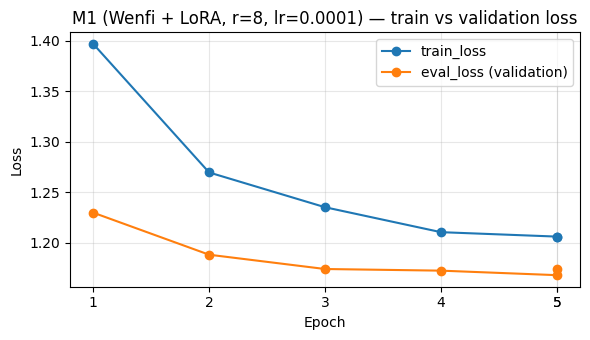

In [14]:
if m1_trainer is not None:
    plot_loss_curve(m1_trainer, f"M1 (Wenfi + LoRA, r={best_r_m1}, lr={best_lr_m1}) — train vs validation loss")
elif "epoch_history" in m1_best_run:
    plot_loss_curve(m1_best_run["epoch_history"], f"M1 (Wenfi + LoRA, r={best_r_m1}, lr={best_lr_m1}) — train vs validation loss")
else:
    print("Loss curve non disponibile (epoch_history non salvata in questa run).")

## 7. Modello 2 — DistilBERT da zero, full fine-tuning su giochi

Esattamente come abbiamo fatto per M1 (valutato prima dell'intervento di LoRA), anche per M2 stabiliamo un punto di partenza testando la rete **prima** di avviare l'addestramento. 

L'obiettivo di questo test non è cercare buone performance, ma fissare un punto di partenza. Partendo da questa misurazione, sarà poi possibile evidenziare il **reale salto di qualità** ottenuto grazie al processo di Full Fine-Tuning.

In [15]:
m2_tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")


def build_m2_model(cfg):
    """Istanzia DistilBERT-base da zero, senza alcun adattamento precedente."""
    return AutoModelForSequenceClassification.from_pretrained(
        "distilbert-base-uncased",
        num_labels=NUM_LABELS, id2label=id2label, label2id=label2id,
    )


# Baseline "no training": misura il punto di partenza di DistilBERT-base
# prima di qualsiasi fine-tuning, confrontabile con m1_raw_result
game_test_probs_m2_raw, m2_raw_result = valuta_modello_grezzo(
    "distilbert-base-uncased", m2_tokenizer, game_test_df, "M2 (no training) su giochi", device_torch,
)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[M2 (no training) su giochi] acc=0.341 f1_macro=0.279 precision_macro=0.367 recall_macro=0.341 auc=0.538


In [16]:
m2_probs_path = f"{M2_DIR}/test_probs.npy"

if os.path.isdir(M2_DIR) and os.path.exists(m2_probs_path):
    # modello completo trovato su disco
    m2_model           = AutoModelForSequenceClassification.from_pretrained(M2_DIR).to(device_torch)
    game_test_probs_m2 = np.load(m2_probs_path)
    m2_result          = json.load(open(f"{M2_DIR}/result.json"))
    m2_best_run        = json.load(open(f"{M2_DIR}/best_run.json"))
    m2_trainer         = None
    best_lr_m2         = m2_best_run["lr"]
    print("M2: modello caricato da disco, training saltato.")

else:
    m2_trainer, m2_best_run, game_test_probs_m2, m2_result, m2_search_results = esegui_pipeline_completa(
        nome_modello="M2 finale (DistilBERT Full Fine-Tuning)",
        tokenizer=m2_tokenizer,
        build_model_fn=build_m2_model,
        configs=m2_configs,
        train_df=game_train_df,
        val_df=game_val_df,
        test_df=game_test_df,
        output_subdir="m2_distilbert_games",
    )
    m2_model   = m2_trainer.model
    best_lr_m2 = m2_best_run["lr"]

    # M2 è standalone: salva il modello completo (a differenza di M1 che salva solo l'adapter)
    m2_model.save_pretrained(M2_DIR)
    m2_tokenizer.save_pretrained(M2_DIR)
    np.save(m2_probs_path, game_test_probs_m2)
    json.dump(m2_result, open(f"{M2_DIR}/result.json", "w"))
    json.dump(
        {k: v for k, v in m2_best_run.items() if k not in ("confusion_matrix",)},
        open(f"{M2_DIR}/best_run.json", "w"),
    )
    print("M2: modello salvato.")

Map:   0%|          | 0/8400 [00:00<?, ? examples/s]

Map:   0%|          | 0/1800 [00:00<?, ? examples/s]


=== A: lr=2e-5, ep=3 ===


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, 

...

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]



Migliore config per m2_distilbert_games: A: lr=2e-5, ep=3 (val_f1_macro=0.7365, composite_score=0.7365)
                        M2 finale (DistilBERT Full Fine-Tuning) — riepilogo di tutte le config                       
---------------------------------------------------------------------------------------------------------------------
     config_name  lr  epochs  val_f1_macro  val_accuracy  overfit_ratio  composite_score  train_time_sec  peak_mem_mb
A: lr=2e-5, ep=3 0.0       3        0.7365        0.7372         0.0000           0.7365        329.6743    5496.9144
B: lr=5e-5, ep=3 0.0       3        0.7453        0.7450         0.0581           0.7237        333.4018    6303.3764
C: lr=2e-5, ep=5 0.0       5        0.7366        0.7344         0.0598           0.7146        555.5493    6302.2899
[M2 finale (DistilBERT Full Fine-Tuning) finale] acc=0.723 f1_macro=0.723 precision_macro=0.723 recall_macro=0.723 auc=0.888


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

M2: modello salvato.


In [17]:
if "epoch_history" in m2_best_run:
    tabella_epoche_m2 = pd.DataFrame(m2_best_run["epoch_history"]).set_index("epoch")
    stampa_tabella(
        tabella_epoche_m2,
        titolo=f"M2 (full fine-tune) — andamento per epoca (config vincente: {m2_best_run['config_name']})",
        decimali=4,
    )


  M2 (full fine-tune) — andamento per epoca (config vincente: A: lr=2e-5, ep=3)  
---------------------------------------------------------------------------------
       train_loss  eval_loss  eval_accuracy  eval_f1_macro
epoch                                                     
1          1.5760     1.2434         0.7228         0.7212
2          1.1805     1.2098         0.7333         0.7352
3          1.0314     1.2033         0.7372         0.7365


### Diagnostica: curva di loss di M2 (configurazione migliore)


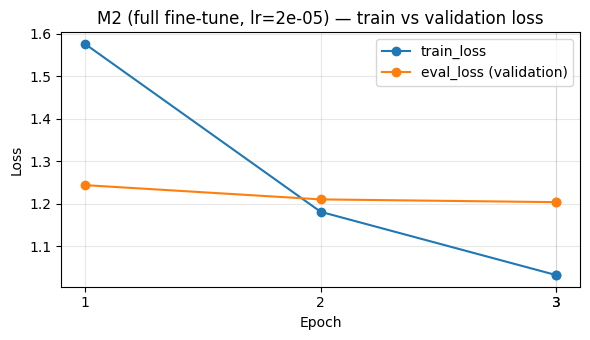

In [18]:
if m2_trainer is not None:
    plot_loss_curve(m2_trainer, f"M2 (full fine-tune, lr={best_lr_m2}) — train vs validation loss")
elif "epoch_history" in m2_best_run:
    plot_loss_curve(m2_best_run["epoch_history"], f"M2 (full fine-tune, lr={best_lr_m2}) — train vs validation loss")
else:
    print("Loss curve non disponibile (epoch_history non salvata in questa run).")

### Baseline: BERT-base (nessun training)

Come per M2 (dove valutiamo DistilBERT prima del full fine-tuning), valutiamo qui BERT-base **prima** dell'addestramento e poi successivamente come si comporta dopo aver appreso tramite Full Fine-Tuning


In [19]:
bert_tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")


def build_bert_model(cfg):
    """Istanzia BERT-base-uncased da zero, usato come sanity check architetturale contro DistilBERT."""
    return AutoModelForSequenceClassification.from_pretrained(
        "bert-base-uncased",
        num_labels=NUM_LABELS,
        id2label=id2label,
        label2id=label2id,
    )


# Baseline "no training": punto di partenza di BERT prima del fine-tuning,
# confrontabile con m2_raw_result per isolare il contributo dell'architettura
print("\n[Valutazione] BERT-base sui videogiochi...")
game_test_probs_bert_raw, bert_raw_result = valuta_modello_grezzo(
    hf_path="bert-base-uncased",
    tokenizer=bert_tokenizer,
    test_df=game_test_df,
    label_name="BERT-base (no training) su giochi",
    device=device_torch,
)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]


[Valutazione] BERT-base sui videogiochi...


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[BERT-base (no training) su giochi] acc=0.331 f1_macro=0.188 precision_macro=0.533 recall_macro=0.331 auc=0.446


In [20]:
bert_probs_path = f"{BERT_DIR}/test_probs.npy"

if os.path.isdir(BERT_DIR) and os.path.exists(bert_probs_path):
    bert_model           = AutoModelForSequenceClassification.from_pretrained(BERT_DIR).to(device_torch)
    game_test_probs_bert = np.load(bert_probs_path)
    bert_result          = json.load(open(f"{BERT_DIR}/result.json"))
    bert_best_run        = json.load(open(f"{BERT_DIR}/best_run.json"))
    bert_trainer         = None
    best_lr_bert         = bert_best_run["lr"]
    print("BERT: modello caricato da disco, training saltato.")

else:
    bert_trainer, bert_best_run, game_test_probs_bert, bert_result, bert_search_results = esegui_pipeline_completa(
        nome_modello="BERT-base (full fine-tune)",
        tokenizer=bert_tokenizer,
        build_model_fn=build_bert_model,
        configs=bert_configs,
        train_df=game_train_df,
        val_df=game_val_df,
        test_df=game_test_df,
        output_subdir="m3_bert_games",
    )
    bert_model   = bert_trainer.model
    best_lr_bert = bert_best_run["lr"]

    bert_model.save_pretrained(BERT_DIR)
    bert_tokenizer.save_pretrained(BERT_DIR)
    np.save(bert_probs_path, game_test_probs_bert)
    json.dump(bert_result, open(f"{BERT_DIR}/result.json", "w"))
    json.dump(
        {k: v for k, v in bert_best_run.items() if k not in ("confusion_matrix",)},
        open(f"{BERT_DIR}/best_run.json", "w"),
    )
    print("BERT: modello salvato.")

Map:   0%|          | 0/8400 [00:00<?, ? examples/s]

Map:   0%|          | 0/1800 [00:00<?, ? examples/s]


=== A: lr=2e-5, ep=3 ===


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.12/dist-packag

...

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]



Migliore config per m3_bert_games: A: lr=2e-5, ep=3 (val_f1_macro=0.7575, composite_score=0.7540)
                              BERT-base (full fine-tune) — riepilogo di tutte le config                              
---------------------------------------------------------------------------------------------------------------------
     config_name  lr  epochs  val_f1_macro  val_accuracy  overfit_ratio  composite_score  train_time_sec  peak_mem_mb
A: lr=2e-5, ep=3 0.0       3        0.7575        0.7572         0.0093           0.7540        649.3170    9396.3638
B: lr=5e-5, ep=3 0.0       3        0.7542        0.7539         0.1060           0.7142        656.8413   10713.3834
C: lr=2e-5, ep=5 0.0       5        0.7578        0.7567         0.1043           0.7183       1094.9566   10713.4561
[BERT-base (full fine-tune) finale] acc=0.745 f1_macro=0.746 precision_macro=0.747 recall_macro=0.745 auc=0.899


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

BERT: modello salvato.


In [21]:
if "epoch_history" in bert_best_run:
    tabella_epoche_bert = pd.DataFrame(bert_best_run["epoch_history"]).set_index("epoch")
    stampa_tabella(
        tabella_epoche_bert,
        titolo=f"BERT-base (full fine-tune) — andamento per epoca (config vincente: {bert_best_run['config_name']})",
        decimali=4,
    )


  BERT-base (full fine-tune) — andamento per epoca (config vincente: A: lr=2e-5, ep=3)  
----------------------------------------------------------------------------------------
       train_loss  eval_loss  eval_accuracy  eval_f1_macro
epoch                                                     
1          1.5390     1.1936         0.7428         0.7447
2          1.1271     1.1470         0.7539         0.7550
3          0.9302     1.1577         0.7572         0.7575


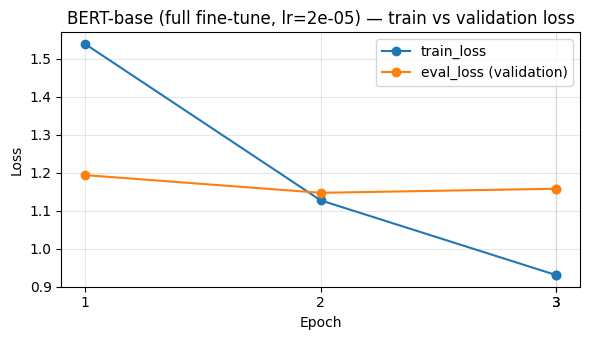

In [22]:
if bert_trainer is not None:
    plot_loss_curve(bert_trainer, f"BERT-base (full fine-tune, lr={best_lr_bert}) — train vs validation loss")
elif "epoch_history" in bert_best_run:
    plot_loss_curve(bert_best_run["epoch_history"], f"BERT-base (full fine-tune, lr={best_lr_bert}) — train vs validation loss")
else:
    print("Loss curve non disponibile (epoch_history non salvata in questa run).")

### DistilBERT vs BERT-base, vale la pena la scelta?

M2 usa DistilBERT principalmente per restare coerente con M1 (che parte
obbligatoriamente da Wenfi, un checkpoint DistilBERT). Ma quanto "costa"
questa scelta in termini di performance? Ripetiamo **esattamente lo stesso
esperimento**  usando `bert-base-uncased` al posto di
`distilbert-base-uncased` — l'unica variabile che cambia è l'architettura.


In [26]:
#scarta il valore "trainable" che qui non serve: confrontiamo solo i totali
_, m2_distilbert_total = count_trainable_params(m2_model)
_, bert_total          = count_trainable_params(bert_model)

arch_comparison = pd.DataFrame([
    {
        "model"         : "DistilBERT (M2)",
        "accuracy"      : m2_result["accuracy"],
        "f1_macro"      : m2_result["f1_macro"],
        "train_time_sec": round(m2_best_run["train_time_sec"], 1),
        "peak_mem_MB"   : round(m2_best_run["peak_mem_mb"]) if pd.notna(m2_best_run["peak_mem_mb"]) else "N/A (no GPU)",
        "n_params"      : f"{m2_distilbert_total:,}",
    },
    {
        "model"         : "BERT-base (sanity check)",
        "accuracy"      : bert_result["accuracy"],
        "f1_macro"      : bert_result["f1_macro"],
        "train_time_sec": round(bert_best_run["train_time_sec"], 1),
        # bert_best_run["peak_mem_mb"] == se stesso fallisce se è NaN (NaN != NaN per definizione)
        "peak_mem_MB"   : round(bert_best_run["peak_mem_mb"]) if bert_best_run["peak_mem_mb"] == bert_best_run["peak_mem_mb"] else "N/A (no GPU)",
        "n_params"      : f"{bert_total:,}",
    },
]).set_index("model")

stampa_tabella(arch_comparison, titolo="DistilBERT vs BERT-base, stesso identico esperimento")

f1_gap      = bert_result["f1_macro"] - m2_result["f1_macro"]
tempo_ratio = bert_best_run["train_time_sec"] / m2_best_run["train_time_sec"]
mem_ratio   = bert_best_run["peak_mem_mb"]    / m2_best_run["peak_mem_mb"]

print(f"\nDifferenza F1-macro (BERT-base − DistilBERT): {f1_gap:+.3f}")
print(f"Costo:  {tempo_ratio:.1f}x tempo di training  |  {mem_ratio:.1f}x VRAM")

if abs(f1_gap) < 0.02:
    print(
        f"-> Differenza trascurabile: DistilBERT raggiunge prestazioni equivalenti "
        f"in {tempo_ratio:.1f}x meno tempo e con {mem_ratio:.1f}x meno VRAM. "
        "La scelta architetturale è pienamente giustificata."
    )
else:
    winner = "BERT-base" if f1_gap > 0 else "DistilBERT"
    print(
        f"-> {winner} guadagna {abs(f1_gap):.3f} di F1-macro ma con {tempo_ratio:.1f}x il tempo di training e "
        f"{mem_ratio:.1f}x la VRAM. DistilBERT rimane la scelta difendibile: il margine non vale il costo."
    )

                 DistilBERT vs BERT-base, stesso identico esperimento                 
--------------------------------------------------------------------------------------
                          accuracy  f1_macro  train_time_sec  peak_mem_MB     n_params
model                                                                                 
DistilBERT (M2)              0.723     0.723           329.7         5497   66,955,779
BERT-base (sanity check)     0.745     0.746           649.3         9396  109,484,547

Differenza F1-macro (BERT-base − DistilBERT): +0.023
Costo:  2.0x tempo di training  |  1.7x VRAM
-> BERT-base guadagna 0.023 di F1-macro ma con 2.0x il tempo di training e 1.7x la VRAM. DistilBERT rimane la scelta difendibile: il margine non vale il costo.


### Efficienza dei parametri: LoRA (M1) vs Full Fine-tuning (M2 e BERT)

Per contestualizzare le differenze nei tempi di addestramento e nell'occupazione VRAM, analizziamo il numero effettivo di parametri modificati durante il training.

CONFRONTO PARAMETRI ADDESTRABILI
---------------------------------------------------------------------------
 M1 (DistilBERT + LoRA) :     740,355 /  67,696,134 (  1.09%)
 M2 (DistilBERT Full)   :  66,955,779 /  66,955,779 (100.00%)
 BERT-base (Baseline)   : 109,484,547 / 109,484,547 (100.00%)
---------------------------------------------------------------------------


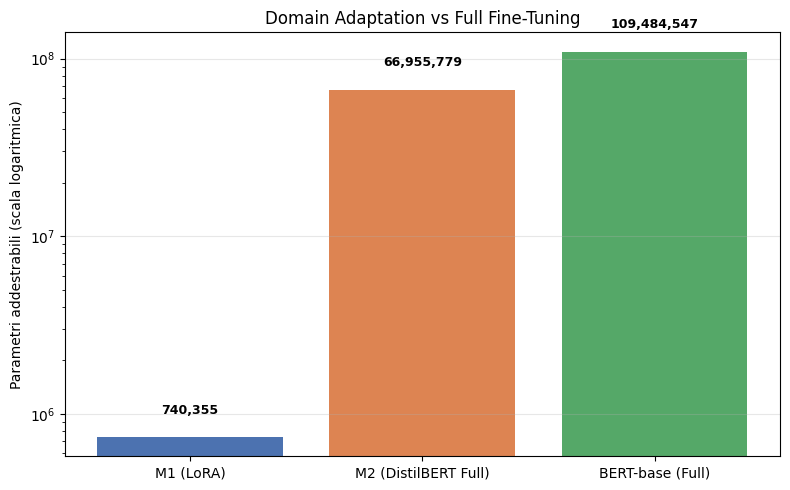

In [27]:
m1_trainable,   m1_total   = count_trainable_params(m1_model)
m2_trainable,   m2_total   = count_trainable_params(m2_model)
bert_trainable, bert_total = count_trainable_params(bert_model)

print("CONFRONTO PARAMETRI ADDESTRABILI")
print("-" * 75)
print(f" M1 (DistilBERT + LoRA) : {m1_trainable:11,} / {m1_total:11,} ({m1_trainable/m1_total*100:6.2f}%)")
print(f" M2 (DistilBERT Full)   : {m2_trainable:11,} / {m2_total:11,} ({m2_trainable/m2_total*100:6.2f}%)")
print(f" BERT-base (Baseline)   : {bert_trainable:11,} / {bert_total:11,} ({bert_trainable/bert_total*100:6.2f}%)")
print("-" * 75)

models           = ["M1 (LoRA)", "M2 (DistilBERT Full)", "BERT-base (Full)"]
trainable_params = [m1_trainable, m2_trainable, bert_trainable]
colors           = ["#4C72B0", "#DD8452", "#55A868"]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, trainable_params, color=colors)

# scala logaritmica sull'asse Y: il divario tra LoRA (~700K) e full fine-tuning (~67M+) 
# è troppo grande per una scala lineare — le barre di M2 e BERT schiaccerebbero M1
plt.yscale("log")
plt.ylabel("Parametri addestrabili (scala logaritmica)")
plt.title("Domain Adaptation vs Full Fine-Tuning")

for bar, val in zip(bars, trainable_params):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        val * 1.3,  # offset moltiplicativo invece che additivo per rispettare la scala log
        f"{val:,}",
        ha="center", va="bottom", fontsize=9, fontweight="bold",
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Tabella di confronto finale


In [28]:
# raccoglie i risultati di tutti e 7 i modelli nella stessa struttura tabellare
comparison_df = pd.DataFrame([
    m3_result, m1_raw_result, m1_result, m2_raw_result, m2_result, bert_raw_result, bert_result,
]).set_index("model")

stampa_tabella(comparison_df, titolo="Confronto sul test set dei giochi")

                                                                               Confronto sul test set dei giochi                                                                                
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
                                                 accuracy  f1_macro  precision_macro  recall_macro  precision_neg  precision_mixed  precision_pos  recall_neg  recall_mixed  recall_pos  roc_auc
model                                                                                                                                                                                           
M3 zero-shot (roberta-large-mnli)                   0.631     0.636            0.702         0.631          0.736            0.476          0.894       0.683         0.732       0.477    0.827
M1 Wenfi (no adattamento) su giochi

# Visualizzazioni del confronto

Mostriamo i risultati ottenuti tramite una metrica di sintesi (F1-Macro) e un'analisi degli errori (matrici di confusione).

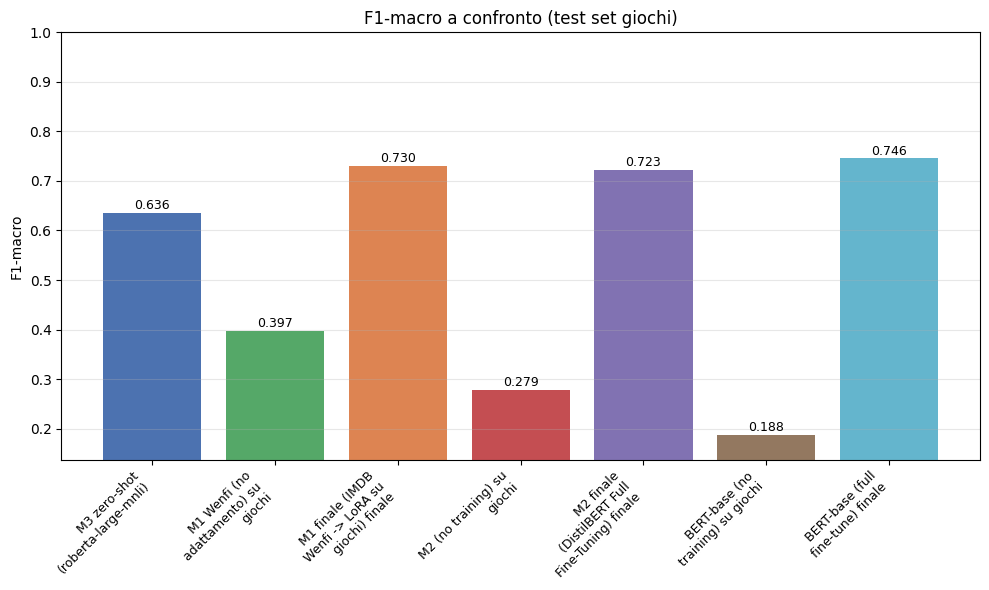

In [29]:
#F1
all_results = [
    m3_result, m1_raw_result, m1_result, m2_raw_result, m2_result, bert_raw_result, bert_result
]
plot_f1_comparison(all_results)


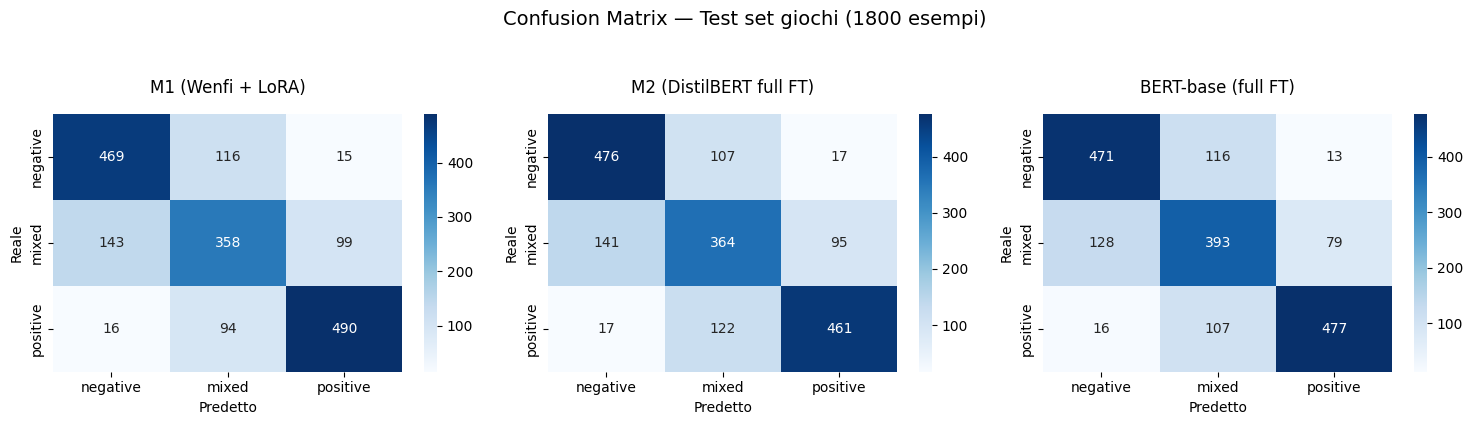

In [30]:
#Matrice di confusione
test_preds_m1   = np.argmax(game_test_probs_m1,   axis=-1)
test_preds_m2   = np.argmax(game_test_probs_m2,   axis=-1)
test_preds_bert = np.argmax(game_test_probs_bert, axis=-1)

predizioni = [test_preds_m1, test_preds_m2, test_preds_bert]
titoli     = ["M1 (Wenfi + LoRA)", "M2 (DistilBERT full FT)", "BERT-base (full FT)"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, preds, title in zip(axes, predizioni, titoli):
    cm = confusion_matrix(game_test_df["label"], preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=LABELS, yticklabels=LABELS)
    ax.set_title(title, pad=15)
    ax.set_xlabel("Predetto")
    ax.set_ylabel("Reale")

plt.suptitle(f"Confusion Matrix — Test set giochi ({len(game_test_df)} esempi)", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

## 9. Test scritti a mano

L'obiettivo è capire come si comportano davanti a recensioni che non seguono gli schemi classici del dataset, ma che includono sarcasmo, gergo tecnico, recensioni brevissime o commenti complessi.

In [31]:
# frasi scritte a mano per testare casi limite: sarcasmo, sentimenti misti,
test = [
    ("10/10 would recommend, best purchase this year.",                                                            2),
    ("Absolute trash, refunded after 20 minutes.",                                                                 0),
    ("yeah it's mid but I still put 200 hours into it lol",                                                        2),
    ("oh great, ANOTHER bug that crashes my save file, love that",                                                 0),
    ("Not perfect, but the soundtrack alone is worth the price.",                                                  2),
    ("Wanted to love this so much. Ended up just disappointed.",                                                   0),
    ("Launched as a broken 3/10. Patches brought it to a solid 7/10. Still not sure it was worth the launch price.", 1),
    ("The combat is chef's kiss. The story is a Wish.com version of Lord of the Rings.",                           1),
]

stress_texts  = [t for t, _ in test]
stress_labels = [l for _, l in test]

if zero_shot_pipe is not None:
    stress_probs_m3 = predict_zero_shot(zero_shot_pipe, stress_texts)
else:
    print("M3 stress test saltato (pipe non caricata).")
    stress_probs_m3 = None

stress_probs_m1   = predict_with_torch_model(m1_model,   wenfi_tokenizer, stress_texts)
stress_probs_m2   = predict_with_torch_model(m2_model,   m2_tokenizer,    stress_texts)
stress_probs_bert = predict_with_torch_model(bert_model, bert_tokenizer,  stress_texts)

if stress_probs_m3 is not None:
    print("--- M3 zero-shot ---")
    evaluate_probs(stress_labels, stress_probs_m3, "M3 su stress test")

print("--- M1 (Wenfi + LoRA) ---")
evaluate_probs(stress_labels, stress_probs_m1, "M1 su stress test")

print("--- M2 (DistilBERT full FT) ---")
evaluate_probs(stress_labels, stress_probs_m2, "M2 su stress test")

print("--- BERT-base (full FT) ---")
evaluate_probs(stress_labels, stress_probs_bert, "BERT-base su stress test")

# libera la pipeline zero-shot dopo lo stress test: è il modello più pesante in memoria
if zero_shot_pipe is not None:
    free_memory(model=zero_shot_pipe.model)
    del zero_shot_pipe

--- M3 zero-shot ---
[M3 su stress test] acc=0.500 f1_macro=0.490 precision_macro=0.633 recall_macro=0.556 auc=0.889
--- M1 (Wenfi + LoRA) ---
[M1 su stress test] acc=0.750 f1_macro=0.739 precision_macro=0.867 recall_macro=0.722 auc=0.822
--- M2 (DistilBERT full FT) ---
[M2 su stress test] acc=0.500 f1_macro=0.381 precision_macro=0.333 recall_macro=0.444 auc=0.883
--- BERT-base (full FT) ---
[BERT-base su stress test] acc=0.750 f1_macro=0.571 precision_macro=0.500 recall_macro=0.667 auc=0.950


In [32]:
stress_data = {
    "text": [t[:40] + "..." for t in stress_texts],
    "true_label": stress_labels,
}

for i, lbl in enumerate(LABELS):
    stress_data[f"M1_{lbl}"] = stress_probs_m1[:, i].round(3)

for i, lbl in enumerate(LABELS):
    stress_data[f"M2_{lbl}"] = stress_probs_m2[:, i].round(3)

for i, lbl in enumerate(LABELS):
    stress_data[f"BERT_{lbl}"] = stress_probs_bert[:, i].round(3)

if stress_probs_m3 is not None:
    for i, lbl in enumerate(LABELS):
        stress_data[f"M3_{lbl}"] = stress_probs_m3[:, i].round(3)

stress_results = pd.DataFrame(stress_data)
stampa_tabella(stress_results, titolo="Stress test scritto a mano — probabilità per modello", index=False)

                                                                             Stress test scritto a mano — probabilità per modello                                                                            
-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
                                       text  true_label  M1_negative  M1_mixed  M1_positive  M2_negative  M2_mixed  M2_positive  BERT_negative  BERT_mixed  BERT_positive  M3_negative  M3_mixed  M3_positive
10/10 would recommend, best purchase thi...           2        0.100     0.292        0.609        0.102     0.150        0.748          0.014       0.076          0.910        0.005     0.048        0.947
Absolute trash, refunded after 20 minute...           0        0.951     0.043        0.007        0.926     0.050        0.024          0.927       0.056          0.017       

# XAI (Explainable AI)

Le metriche di performance, come l'Accuracy e l'F1-Macro, ci dicono quanto i modelli sono accurati, ma non spiegano il perché delle loro decisioni. Per capire se le previsioni siano guidate da segnali linguistici sensati o da semplici coincidenze statistiche del dataset, abbiamo applicato tecniche di Explainable AI (XAI).

In particolare, abbiamo utilizzato la tecnica degli Integrated Gradients: la tecnica misura quanto ogni singola parola della recensione contribuisce al punteggio finale assegnato dal modello alla classe predetta (es. "Positiva",";Mixed" o "Negativa").

Per rendere leggibili questi dati:

1. **Sfondo Verde**: Indica che quel termine ha fornito un contributo positivo, spingendo il modello verso la classificazione corretta.

2. **Sfondo Rosso**: Indica un contributo negativo; ovvero, quel termine ha generato confusione o suggeriva al modello di scegliere una classe diversa.

**Intensità del colore**: Più il colore è marcato, maggiore è stata l'importanza attribuita a quella parola nella decisione finale.

In [34]:
def compute_ig_attributions(model, tokenizer, text, target_class=2, n_steps=50):
    """
    Calcola le attribuzioni per il testo rispetto a una classe target usando LayerIntegratedGradients.
    """
    model.eval()
    
    # Tokenizza
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=256)
    input_ids = inputs["input_ids"].to(model.device)
    attention_mask = inputs["attention_mask"].to(model.device)
    
    # Baseline: usiamo l'ID effettivo del token di PAD del tokenizer (non sempre è 0!)
    pad_token_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0
    baseline_ids = torch.full_like(input_ids, pad_token_id).to(model.device)
    
    # Funzione di forward che accetta anche la maschera di attenzione
    def forward_func(input_ids, attention_mask):
        return model(input_ids=input_ids, attention_mask=attention_mask).logits
    
    # CREAZIONE CORRETTA: Agganciamo l'IG allo strato degli Embeddings!
    lig = LayerIntegratedGradients(forward_func, model.get_input_embeddings())
    
    # Calcola attribuzioni
    attributions, delta = lig.attribute(
        inputs=input_ids, 
        baselines=baseline_ids, 
        target=target_class, 
        additional_forward_args=(attention_mask,), # Passa argomenti extra al forward
        return_convergence_delta=True, 
        n_steps=n_steps
    )
    
    # attributions ha shape (1, seq_len, embed_dim). Sommiamo su embed_dim
    attributions = attributions.sum(dim=-1).squeeze(0)
    
    # Normalizza per lunghezza per evitare che frasi lunghe sballino i punteggi
    attributions = attributions / torch.norm(attributions)
    
    # Decodifica i token in formato testuale
    tokens = tokenizer.convert_ids_to_tokens(input_ids.squeeze(0).tolist())
    special_tokens = set(tokenizer.all_special_tokens) # Estrae tutti i token speciali per pulizia
    
    token_attrib = []
    for i, token in enumerate(tokens):
        if token not in special_tokens:
            # Ripulisce i prefissi di tokenizzazione di BERT (##) e RoBERTa/Distil (Ġ)
            clean_token = token.replace('Ġ', '').replace('##', '')
            # Filtra eventuali token vuoti dopo la pulizia
            if clean_token: 
                token_attrib.append((clean_token, attributions[i].item()))
                
    return token_attrib

def visualize_attributions(token_attrib, top_k=10):
    """
    Mostra le parole con le attribuzioni più alte (in valore assoluto).
    """
    sorted_attrib = sorted(token_attrib, key=lambda x: abs(x[1]), reverse=True)
    print("Top attribuzioni (in valore assoluto):")
    for word, attr in sorted_attrib[:top_k]:
        print(f"  {word}: {attr:.4f}")

In [35]:
mie_recensioni = [
    {
        "review_text": "The graphics are terrible, but I absolutely loved the gameplay and the story is a masterpiece.",
        "target_label": 1  
    },
    {
        "review_text": "The most expensive and least playable game in my entire Steam library. A remarkable achievement.",
        "target_label": 0
    },
    {
        "review_text": "An absolute masterpiece! Best 60 bucks ever spent, the combat system is so fun.",
        "target_label": 2  
    },
    {
        "review_text": "The 'revolutionary AI' they advertised turns out to be three if-statements and a random number generator.",
        "target_label": 0
    },
    {
        "review_text": "They patched it and now it's a completely different game. Went from 1 star to 5, genuinely.",
        "target_label": 2  
    },
    {
        "review_text": "Visually gorgeous but the gameplay is shallow. I admire the art direction while being bored out of my mind.",
        "target_label": 1  
    }
]

modelli = {
    "M1 (Wenfi+LoRA)": (m1_model, wenfi_tokenizer),
    "M2 (DistilBERT full FT)": (m2_model, m2_tokenizer),
    "BERT-base (full FT)": (bert_model, bert_tokenizer)
}

for model_name, (model, tokenizer) in modelli.items():
    print(f"\n{'='*60}")
    print(f"Analisi XAI per {model_name}")
    print('='*60)
    
    for idx, row in enumerate(mie_recensioni):
        text = row["review_text"]
        true_label = row["target_label"]
        label_name = LABELS[true_label]
        
        print(f"\n--- Esempio {idx+1} (Target Reale: {label_name}) ---")
        print(f"Testo analizzato: '{text}'")
        
        # Calcola attribuzioni per la classe reale usando la funzione corretta
        attrib = compute_ig_attributions(
            model, tokenizer, text,
            target_class=true_label,  
            n_steps=30 
        )
        
        # Invece di stampare la lista di testo, invochiamo la magia dell'HTML!
        mostra_testo_evidenziato(
            attrib, 
            titolo=f"Evidenze per la classe '{label_name}'"
        )


Analisi XAI per M1 (Wenfi+LoRA)

--- Esempio 1 (Target Reale: mixed) ---
Testo analizzato: 'The graphics are terrible, but I absolutely loved the gameplay and the story is a masterpiece.'



--- Esempio 2 (Target Reale: negative) ---
Testo analizzato: 'The most expensive and least playable game in my entire Steam library. A remarkable achievement.'



--- Esempio 3 (Target Reale: positive) ---
Testo analizzato: 'An absolute masterpiece! Best 60 bucks ever spent, the combat system is so fun.'



--- Esempio 4 (Target Reale: negative) ---
Testo analizzato: 'The 'revolutionary AI' they advertised turns out to be three if-statements and a random number generator.'



--- Esempio 5 (Target Reale: positive) ---
Testo analizzato: 'They patched it and now it's a completely different game. Went from 1 star to 5, genuinely.'


...


--- Esempio 2 (Target Reale: negative) ---
Testo analizzato: 'The most expensive and least playable game in my entire Steam library. A remarkable achievement.'



--- Esempio 3 (Target Reale: positive) ---
Testo analizzato: 'An absolute masterpiece! Best 60 bucks ever spent, the combat system is so fun.'



--- Esempio 4 (Target Reale: negative) ---
Testo analizzato: 'The 'revolutionary AI' they advertised turns out to be three if-statements and a random number generator.'



--- Esempio 5 (Target Reale: positive) ---
Testo analizzato: 'They patched it and now it's a completely different game. Went from 1 star to 5, genuinely.'



--- Esempio 6 (Target Reale: mixed) ---
Testo analizzato: 'Visually gorgeous but the gameplay is shallow. I admire the art direction while being bored out of my mind.'


## 10. Backup

**Backup ZIP**: Dato che Kaggle cancella `/kaggle/working` a fine sessione se non viene committato, salvo il tutto in uno ZIP per evitare di perdere ore per il training.


In [36]:
comparison_df.to_csv(f"{OUTPUT_DIR}/comparison_results.csv") # Genera un comodo csv da scaricare per farci tabelle sulla relazione o per excel.
stress_results.to_csv(f"{OUTPUT_DIR}/stress_test_results.csv", index=False) # Genera CSV dello stress 

BACKUP_ZIP_BASE = f"{OUTPUT_DIR}/backup_finale" # Crea la root path dell'archivio totale per salvare il sedere dello sviluppatore (dato che Kaggle formatta ad istanza chiusa)
shutil.make_archive(BACKUP_ZIP_BASE, "zip", OUTPUT_DIR) # Genera una palla Zip che includerà Modelli M1, M2, Tokenizers, e CSV
backup_size_mb = os.path.getsize(BACKUP_ZIP_BASE + ".zip") / 1e6 # Estrae metadata OS sul peso dell'archivio generato per informare l'utente
print(f"Backup completo creato: {BACKUP_ZIP_BASE}.zip ({backup_size_mb:.0f} MB) -- scaricalo dal pannello Output di Kaggle") # Appone Print a Schermo

Backup completo creato: /kaggle/working/results_sentiment/backup_finale.zip (656 MB) -- scaricalo dal pannello Output di Kaggle
